# Weighted CatBoost challenger

One predeclared E2 experiment: change only class_weights relative to the unweighted CatBoost baseline. Compute the ratio from Train labels, fit Train and score Validation A. No tuning, calibration, threshold selection or B/Test predictions. Run after the three baseline notebooks. Restart Kernel and Run All for a fresh run.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Libraries and inputs

Use the same dataset, predictors and split manifest as Logistic Regression / Random Forest.

In [2]:
from catboost import CatBoostClassifier



from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, precision_recall_curve, roc_auc_score

from sklearn.pipeline import Pipeline



INPUTS = ['data/processed/research_data_weather_price_holiday_assume_utc.csv', 'docs/predictor_list.csv', 'data/ml_preparation/split_manifest.csv']

EXPECTED = {'train': (57449, 3720), 'validation_a': (7661, 387), 'validation_b': (3115, 180), 'test': (9445, 504)}


## Load and audit splits

Check unique order IDs, valid labels and the expected sample sizes. B/Test are not used for model selection.

In [3]:
features = pd.read_csv(ROOT / INPUTS[1]).feature.tolist()

assert len(features) == len(set(features)) == 21

df = pd.read_csv(ROOT / INPUTS[0])

manifest = pd.read_csv(ROOT / INPUTS[2])

assert df.order_id.is_unique and manifest.order_id.is_unique

selected = manifest.loc[manifest.split.isin(EXPECTED), ['order_id', 'split']]

data = selected.merge(df, on='order_id', how='left', validate='one_to_one', indicator=True)

assert data._merge.eq('both').all()

audit = []

for split, (n, positives) in EXPECTED.items():
    z = data.loc[data.split.eq(split)]
    assert len(z) == n and z.is_late.notna().all()
    assert z.is_late.isin([0, 1]).all() and int(z.is_late.sum()) == positives
    audit.append(dict(split=split, n=n, late=positives))
display(pd.DataFrame(audit))


,split,n,late
0,train,57449,3720
1,validation_a,7661,387
2,validation_b,3115,180
3,test,9445,504


## Prepare features

Use the baseline numeric median and native categorical representation; all learned transformations are fitted on Train.

In [4]:
train = data.loc[data.split.eq('train')].copy()

val = data.loc[data.split.eq('validation_a')].copy()

cat = ['customer_state', 'purchase_weekday']

num = [f for f in features if f not in cat]

for z in (train, val):
    for c in cat:
        z[c] = z[c].map(lambda v: str(v) if pd.notna(v) else np.nan)
    for c in num:
        z[c] = pd.to_numeric(z[c], errors='raise').replace([np.inf, -np.inf], np.nan)

assert not train[features].isna().all().any()

hashes = {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in INPUTS}

lf_hashes = {p: hashlib.sha256((ROOT / p).read_bytes().replace(b'\r\n', b'\n')).hexdigest() for p in INPUTS}


## Compute Train weights and declare the challenger

Use the full-precision ratio of Not Late to Late. No auto_class_weights, scale_pos_weight or sample balancing is added.

In [5]:
y_train = train.is_late.astype(int)
y_validation = val.is_late.astype(int)
n_not_late = int(y_train.eq(0).sum())
n_late = int(y_train.eq(1).sum())
assert n_not_late > 0 and n_late > 0
positive_class_weight = n_not_late / n_late
class_weights = [1.0, positive_class_weight]
catboost_classifier = CatBoostClassifier(
    iterations=100, learning_rate=0.1, depth=6,
    loss_function="Logloss", eval_metric="Logloss",
    random_seed=42, thread_count=4, task_type="CPU",
    use_best_model=False, allow_writing_files=False, verbose=False,
    cat_features=cat, class_weights=class_weights,
)
display(pd.DataFrame([
    dict(label=0, train_orders=n_not_late, weight=1.0),
    dict(label=1, train_orders=n_late, weight=positive_class_weight),
]))


,label,train_orders,weight
0,0,53729,1.00000
1,1,3720,14.44328


## Match the unweighted CatBoost run before fitting

Require a complete baseline comparison with matching input hashes. Check that the only constructor parameter change is class_weights.

In [6]:
baseline_source = None
for candidate in sorted((ROOT / "outputs/tables/machine_learning/ml_catboost_dummy").glob("*/six_model_comparison.csv"), reverse=True):
    previous_hashes = {k.replace("\\", "/"): v for k, v in json.loads((candidate.parent / "input_hashes.json").read_text(encoding="utf-8")).items()}
    if previous_hashes == hashes or previous_hashes == lf_hashes:
        baseline_source = candidate.parent
        break
if baseline_source is None:
    raise FileNotFoundError("Run catboost_dummy.ipynb on the current shared inputs first.")
baseline_plan = json.loads((baseline_source / "experiment_plan.json").read_text(encoding="utf-8"))
challenger_parameters = catboost_classifier.get_params().copy()
assert challenger_parameters.pop("class_weights") == class_weights
assert challenger_parameters == baseline_plan["CatBoost"], "Unexpected parameter change beyond class_weights."
print("Matched baseline:", baseline_source.relative_to(ROOT))


Matched baseline: outputs\tables\ml_catboost_dummy\20261111_152855_922857


## Create run folders and save the plan

Write the exact weights, parameters, baseline source, hashes and versions before fitting.

In [7]:
run = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
tables = ROOT / "outputs/tables/machine_learning/ml_catboost_weighted" / run
figures = ROOT / "outputs/figures/ml_catboost_weighted" / run
saved = ROOT / "outputs/models/ml_catboost_weighted" / run
for path in [tables, figures, saved]:
    path.mkdir(parents=True, exist_ok=False)
pd.DataFrame(audit).to_csv(tables / "input_audit.csv", index=False)
pd.DataFrame({
    "feature": features,
    "missing_train": train[features].isna().sum().to_numpy(),
    "unique_train": train[features].nunique().to_numpy(),
}).to_csv(tables / "feature_audit.csv", index=False)
for filename, values in [("input_hashes.json", hashes), ("input_lf_hashes.json", lf_hashes)]:
    (tables / filename).write_text(json.dumps(values, indent=2), encoding="utf-8")
versions = {name: importlib.metadata.version(name) for name in [
    "numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib", "catboost",
]}
versions["python"] = platform.python_version()
(tables / "package_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
plan = {
    "purpose": "E2: single weighted CatBoost challenger on Validation A",
    "CatBoostWeighted": catboost_classifier.get_params(),
    "train_class_counts": {"not_late": n_not_late, "late": n_late},
    "weight_ratio": positive_class_weight,
    "baseline_run": str(baseline_source.relative_to(ROOT)),
    "fit_split": "train", "score_split": "validation_a",
    "tuning": False, "weighting": "class_weights from Train only", "early_stopping": False,
    "calibration": False, "threshold_selection": False,
    "preprocessing": "Train median + categorical missing string, native categorical handling; unchanged from CatBoost baseline",
}
(tables / "experiment_plan.json").write_text(json.dumps(plan, indent=2), encoding="utf-8")
print("Run:", run)


Run: 20261111_153704_495324


## Fit the weighted CatBoost pipeline on Train

The numeric imputer and categorical handling are identical to the matched baseline. Validation labels do not enter this cell.

In [8]:
catboost_preprocessor = ColumnTransformer(
    [
        ("numeric", SimpleImputer(strategy="median"), num),
        ("category", SimpleImputer(strategy="constant", fill_value="__MISSING__"), cat),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")
catboost_pipeline = Pipeline([
    ("preprocessing", catboost_preprocessor),
    ("classifier", catboost_classifier),
])
start = time.perf_counter()
catboost_pipeline.fit(train[features], y_train)
catboost_training_seconds = time.perf_counter() - start
print("CatBoost training seconds:", round(catboost_training_seconds, 3))


CatBoost training seconds: 10.223


## Evaluate Validation A and verify the saved pipeline

Score raw probabilities using the same four metrics and verify model reload. No threshold is applied.

In [9]:
catboost_probabilities = catboost_pipeline.predict_proba(val[features])[:, 1]
assert np.isfinite(catboost_probabilities).all()
assert ((catboost_probabilities >= 0) & (catboost_probabilities <= 1)).all()
joblib.dump(catboost_pipeline, saved / "CatBoostWeighted.joblib")
np.testing.assert_allclose(
    joblib.load(saved / "CatBoostWeighted.joblib").predict_proba(val[features])[:, 1],
    catboost_probabilities,
)
catboost_metrics = dict(
    model="CatBoostWeighted", split="validation_a", probability_type="raw",
    n=len(y_validation), late=int(y_validation.sum()), prevalence=float(y_validation.mean()),
    AP=average_precision_score(y_validation, catboost_probabilities),
    ROC_AUC=roc_auc_score(y_validation, catboost_probabilities),
    Brier=brier_score_loss(y_validation, catboost_probabilities),
    LogLoss=log_loss(y_validation, catboost_probabilities, labels=[0, 1]),
)
catboost_predictions = pd.DataFrame(dict(
    order_id=val.order_id.to_numpy(), split="validation_a", model="CatBoostWeighted",
    y_true=y_validation.to_numpy(), probability=catboost_probabilities,
    prediction=np.nan, threshold=np.nan, probability_type="raw",
))
display(pd.DataFrame([catboost_metrics]))


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,CatBoostWeighted,validation_a,raw,7661,387,0.050516,0.079147,0.602951,0.159419,0.499574


## Export the challenger run

The baseline artifacts are not overwritten.

In [10]:
metrics = pd.DataFrame([catboost_metrics])
validation_predictions = catboost_predictions
metrics.to_csv(tables / "validation_a_metrics.csv", index=False)
validation_predictions.to_csv(tables / "validation_predictions.csv", index=False)
log = dict(
    model="CatBoostWeighted", training_seconds=catboost_training_seconds,
    parameters=catboost_classifier.get_params(),
    fitted_parameters=catboost_classifier.get_all_params(),
    weighting="class_weights from Train only", class_weights=class_weights,
    baseline_run=str(baseline_source.relative_to(ROOT)),
)
(tables / "experiment_log.json").write_text(json.dumps([log], indent=2, default=str), encoding="utf-8")


3117

## Compare weighting and all seven configurations

Verify input hashes, validation IDs/labels and recorded metrics. This comparison supports the next selection step; it does not freeze a winner.

In [11]:
parts = [metrics]
prediction_parts = [validation_predictions]
comparison_sources = {}
expected_labels = val.set_index("order_id").is_late.astype(int).sort_index()
for folder, expected_models in [
    ("ml_logistic_random_forest", {"LogisticRegression", "RandomForest"}),
    ("ml_lightgbm_xgboost", {"LightGBM", "XGBoost"}),
    ("ml_catboost_dummy", {"CatBoost", "DummyClassifier"}),
]:
    for source in ([baseline_source / "input_hashes.json"] if folder == "ml_catboost_dummy" else sorted((ROOT / "outputs/tables/machine_learning" / folder).glob("*/input_hashes.json"), reverse=True)):
        previous_hashes = {k.replace("\\", "/"): v for k, v in json.loads(source.read_text(encoding="utf-8")).items()}
        if previous_hashes != hashes and previous_hashes != lf_hashes:
            continue
        previous_predictions = pd.read_csv(source.parent / "validation_predictions.csv")
        previous_metrics = pd.read_csv(source.parent / "validation_a_metrics.csv")
        assert set(previous_metrics.model) == set(previous_predictions.model) == expected_models
        assert previous_metrics.model.is_unique
        for model_name, group in previous_predictions.groupby("model"):
            assert group.split.eq("validation_a").all()
            observed = group.set_index("order_id").y_true.astype(int).sort_index()
            pd.testing.assert_series_equal(expected_labels, observed, check_names=False)
            calculated = [
                average_precision_score(group.y_true, group.probability),
                roc_auc_score(group.y_true, group.probability),
                brier_score_loss(group.y_true, group.probability),
                log_loss(group.y_true, group.probability, labels=[0, 1]),
            ]
            recorded = previous_metrics.loc[previous_metrics.model.eq(model_name), ["AP", "ROC_AUC", "Brier", "LogLoss"]].iloc[0].to_numpy(dtype=float)
            # Float32 model probabilities may round differently after CSV reload as float64.
            np.testing.assert_allclose(calculated, recorded, rtol=1e-8, atol=1e-10)
        parts.append(previous_metrics)
        prediction_parts.append(previous_predictions)
        comparison_sources[folder] = str(source.parent.relative_to(ROOT))
        break
    else:
        raise FileNotFoundError(f"No matching baseline run in {folder}; run its notebook first.")
comparison = pd.concat(parts, ignore_index=True).sort_values("AP", ascending=False)
assert len(comparison) == 7 and comparison.model.is_unique
assert comparison.n.eq(len(val)).all() and comparison.late.eq(int(y_validation.sum())).all()
comparison.to_csv(tables / "seven_model_comparison.csv", index=False)
(tables / "comparison_source.json").write_text(json.dumps(comparison_sources, indent=2), encoding="utf-8")
all_predictions = pd.concat(prediction_parts, ignore_index=True)
display(comparison)

weighting_comparison = comparison.loc[comparison.model.isin(["CatBoost", "CatBoostWeighted"])].copy()
weighting_comparison["weighting"] = weighting_comparison.model.map({"CatBoost": "none", "CatBoostWeighted": "class_weights"})
weighting_comparison.to_csv(tables / "weighting_comparison.csv", index=False)
baseline_metrics = weighting_comparison.set_index("model").loc["CatBoost"]
weighted_metrics = weighting_comparison.set_index("model").loc["CatBoostWeighted"]
delta = pd.DataFrame([
    dict(metric=name, baseline=float(baseline_metrics[name]),
         weighted=float(weighted_metrics[name]),
         weighted_minus_baseline=float(weighted_metrics[name] - baseline_metrics[name]))
    for name in ["AP", "ROC_AUC", "Brier", "LogLoss"]
])
delta.to_csv(tables / "weighting_metric_changes.csv", index=False)
display(delta)
print("Model selection and selected_config.json are deferred to E3. B/Test remain unscored.")


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
5,CatBoost,validation_a,raw,7661,387,0.050516,0.092855,0.655757,0.047227,0.192596
1,LogisticRegression,validation_a,raw,7661,387,0.050516,0.091637,0.642369,0.047720,0.196408
0,CatBoostWeighted,validation_a,raw,7661,387,0.050516,0.079147,0.602951,0.159419,0.499574
4,XGBoost,validation_a,raw,7661,387,0.050516,0.076845,0.596653,0.047978,0.199795
2,RandomForest,validation_a,raw,7661,387,0.050516,0.074766,0.604052,0.048191,0.200893
3,LightGBM,validation_a,raw,7661,387,0.050516,0.073623,0.582513,0.048189,0.201357
6,DummyClassifier,validation_a,raw,7661,387,0.050516,0.050516,0.500000,0.048166,0.201833


,metric,baseline,weighted,weighted_minus_baseline
0,AP,0.092855,0.079147,-0.013708
1,ROC_AUC,0.655757,0.602951,-0.052806
2,Brier,0.047227,0.159419,0.112192
3,LogLoss,0.192596,0.499574,0.306978


Model selection and selected_config.json are deferred to E3. B/Test remain unscored.


## Inspect precision-recall curves

Weighting may improve ranking and worsen raw probability quality. Do not select a threshold on Validation A.

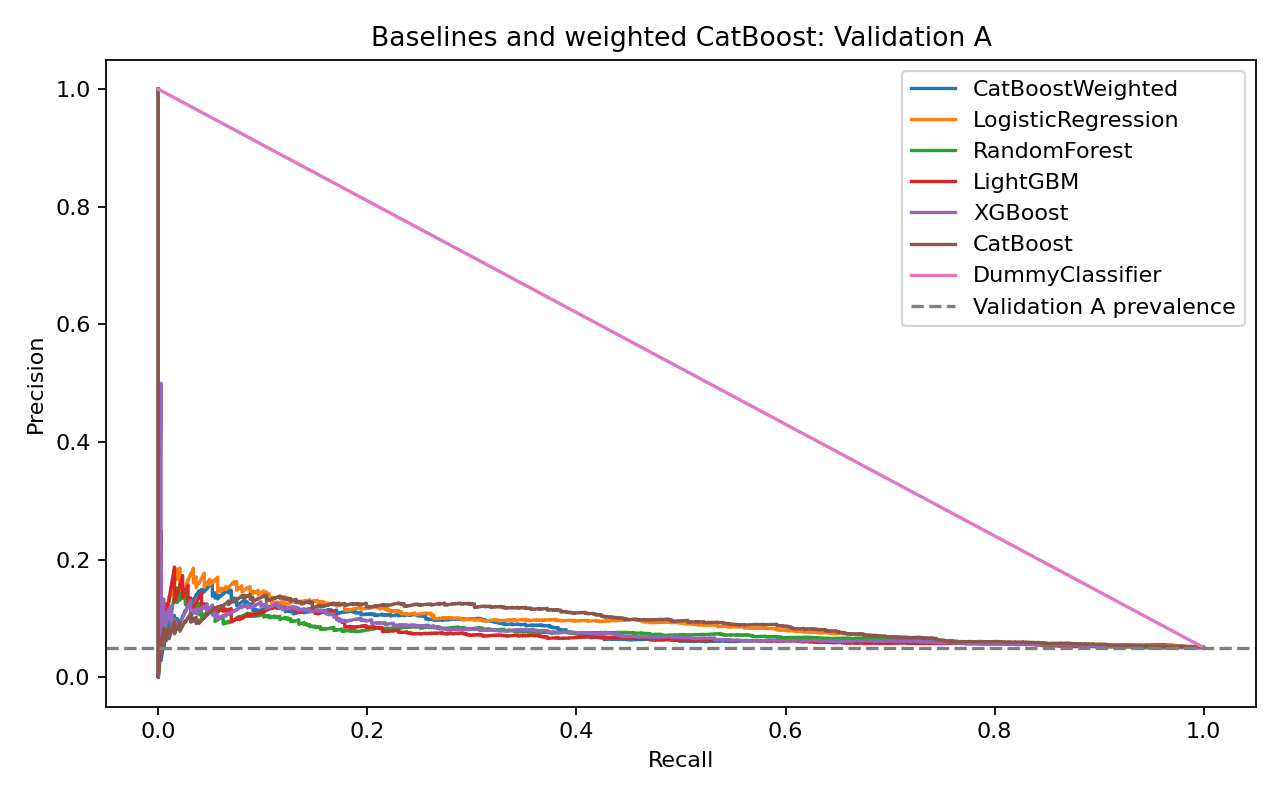

Results: C:\Users\LENOVO\OneDrive\Desktop\PTTK\outputs\tables\ml_catboost_weighted\20261111_153704_495324
B/Test not scored. No weighting, calibration or threshold selected.


In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, group in all_predictions.groupby("model", sort=False):
    precision, recall, _ = precision_recall_curve(group.y_true, group.probability)
    ax.plot(recall, precision, label=name)
ax.axhline(float(y_validation.mean()), color="gray", linestyle="--", label="Validation A prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Baselines and weighted CatBoost: Validation A")
ax.legend()
fig.tight_layout()
path = figures / "validation_a_pr_curve.png"
fig.savefig(path, dpi=160)
display(Image(filename=str(path)))
plt.close(fig)
print("Results:", tables)
print("B/Test not scored. No weighting, calibration or threshold selected.")
